<a href="https://colab.research.google.com/github/nisabulut/digital-image-processing/blob/main/2_1_goruntu_isleme.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!apt-get install libopencv-dev -y

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following additional packages will be installed:
  at-spi2-common at-spi2-core gsettings-desktop-schemas
  gstreamer1.0-plugins-base libatk-bridge2.0-0t64 libatk1.0-0t64
  libatspi2.0-0t64 libavcodec-dev libavformat-dev libavutil-dev libcdparanoia0
  libcharls2 libdc1394-dev libdouble-conversion3 libevdev2 libexif-dev
  libexif-doc libexif12 libgdcm-dev libgdcm3.0t64 libgl2ps1.4 libglew2.2
  libgphoto2-6t64 libgphoto2-dev libgphoto2-l10n libgphoto2-port12t64
  libgstreamer-plugins-base1.0-0 libgtk-3-0t64 libgtk-3-bin libgtk-3-common
  libgudev-1.0-0 libimath-3-1-29t64 libimath-dev libinput-bin libinput10
  libmd4c0 libmtdev1t64 libopencv-calib3d-dev libopencv-calib3d406t64
  libopencv-contrib-dev libopencv-contrib406t64 libopencv-core-dev
  libopencv-core406t64 libopencv-dnn-dev libopencv-dnn406t64
  libopencv-features2d-dev libopencv-features2d406t64 libopencv-flann-dev
  libopencv-fla

In [ ]:
%%writefile odev.cpp
#include <opencv2/opencv.hpp>
#include <iostream>
#include <chrono>

using namespace cv;
using namespace std;
using namespace std::chrono;

int main() {
    /
    Mat img_gray = imread("image2.2.jpg", IMREAD_GRAYSCALE);
    if(img_gray.empty()) {
        cout << "Gorsel bulunamadi! Lutfen test_image.jpg dosyasini Colab'e yukleyin." << endl;
        return -1;
    }

    Mat img_6bit;
    bitwise_and(img_gray, 252, img_6bit);
    imwrite("quantized_6bit.jpg", img_6bit);
    cout << "[BASARILI] 6-bit nicemleme tamamlandi ve 'quantized_6bit.jpg' olarak kaydedildi." << endl;

    // ==========================================
    // ÇALIŞMA: Mekânsal Çözünürlük
    // ==========================================
    Mat img_bgr = imread("image2.2.jpg");
    Mat gray_base;

    cvtColor(img_bgr, gray_base, COLOR_BGR2GRAY);
    cout << "\nOrijinal Boyut: " << gray_base.cols << "x" << gray_base.rows << endl;

    auto start_cpu = high_resolution_clock::now();

    Mat cpu_half, cpu_double;
    resize(gray_base, cpu_half, Size(), 0.5, 0.5, INTER_LINEAR);
    resize(gray_base, cpu_double, Size(), 2.0, 2.0, INTER_LINEAR);

    auto end_cpu = high_resolution_clock::now();
    duration<double> cpu_time = end_cpu - start_cpu;
    cout << "CPU Toplam Islem Suresi: " << cpu_time.count() << " saniye" << endl;

    return 0;
}

Overwriting odev.cpp


In [ ]:

!apt-get install libopencv-dev -y

!g++ -o odev odev.cpp `pkg-config --cflags --libs opencv4`

!./odev

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
libopencv-dev is already the newest version (4.6.0+dfsg-13.1ubuntu1).
0 upgraded, 0 newly installed, 0 to remove and 33 not upgraded.
[BASARILI] 6-bit nicemleme tamamlandi ve 'quantized_6bit.jpg' olarak kaydedildi.

Orijinal Boyut: 3840x2160
CPU Toplam Islem Suresi: 0.0271996 saniye


--- Orijinal Resim ---


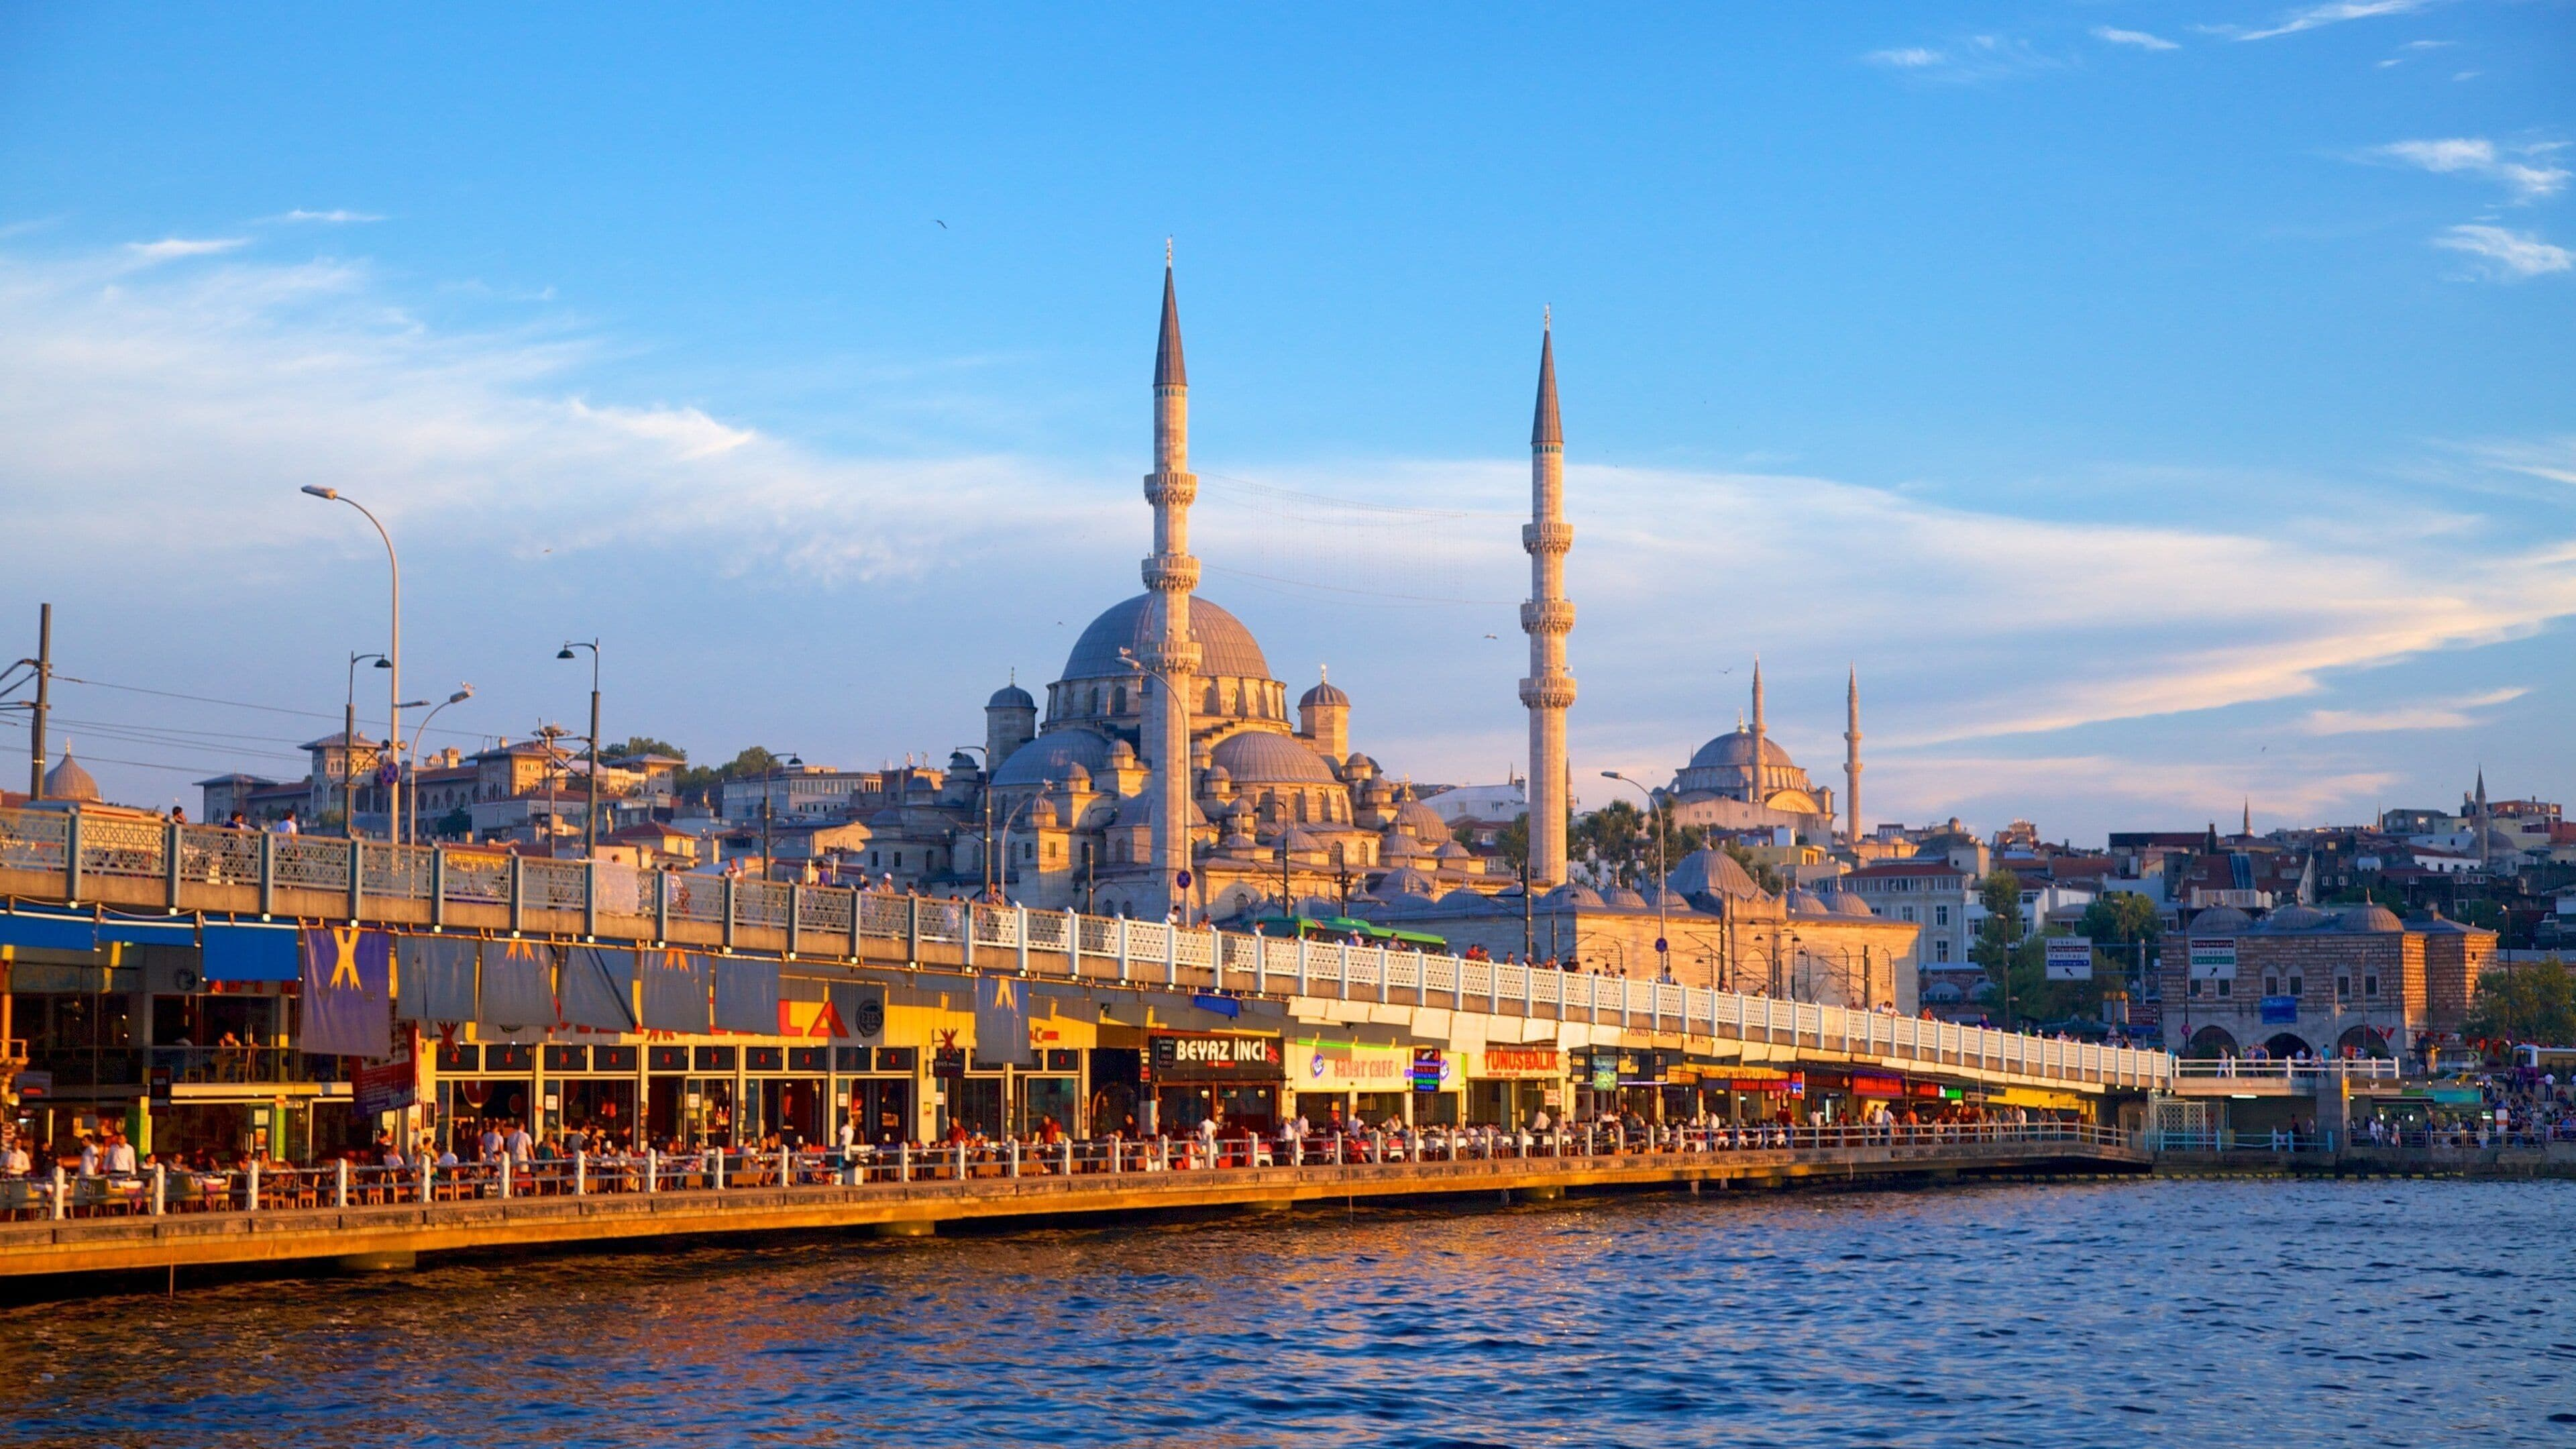

--- Quantize Sonrası Resim ---


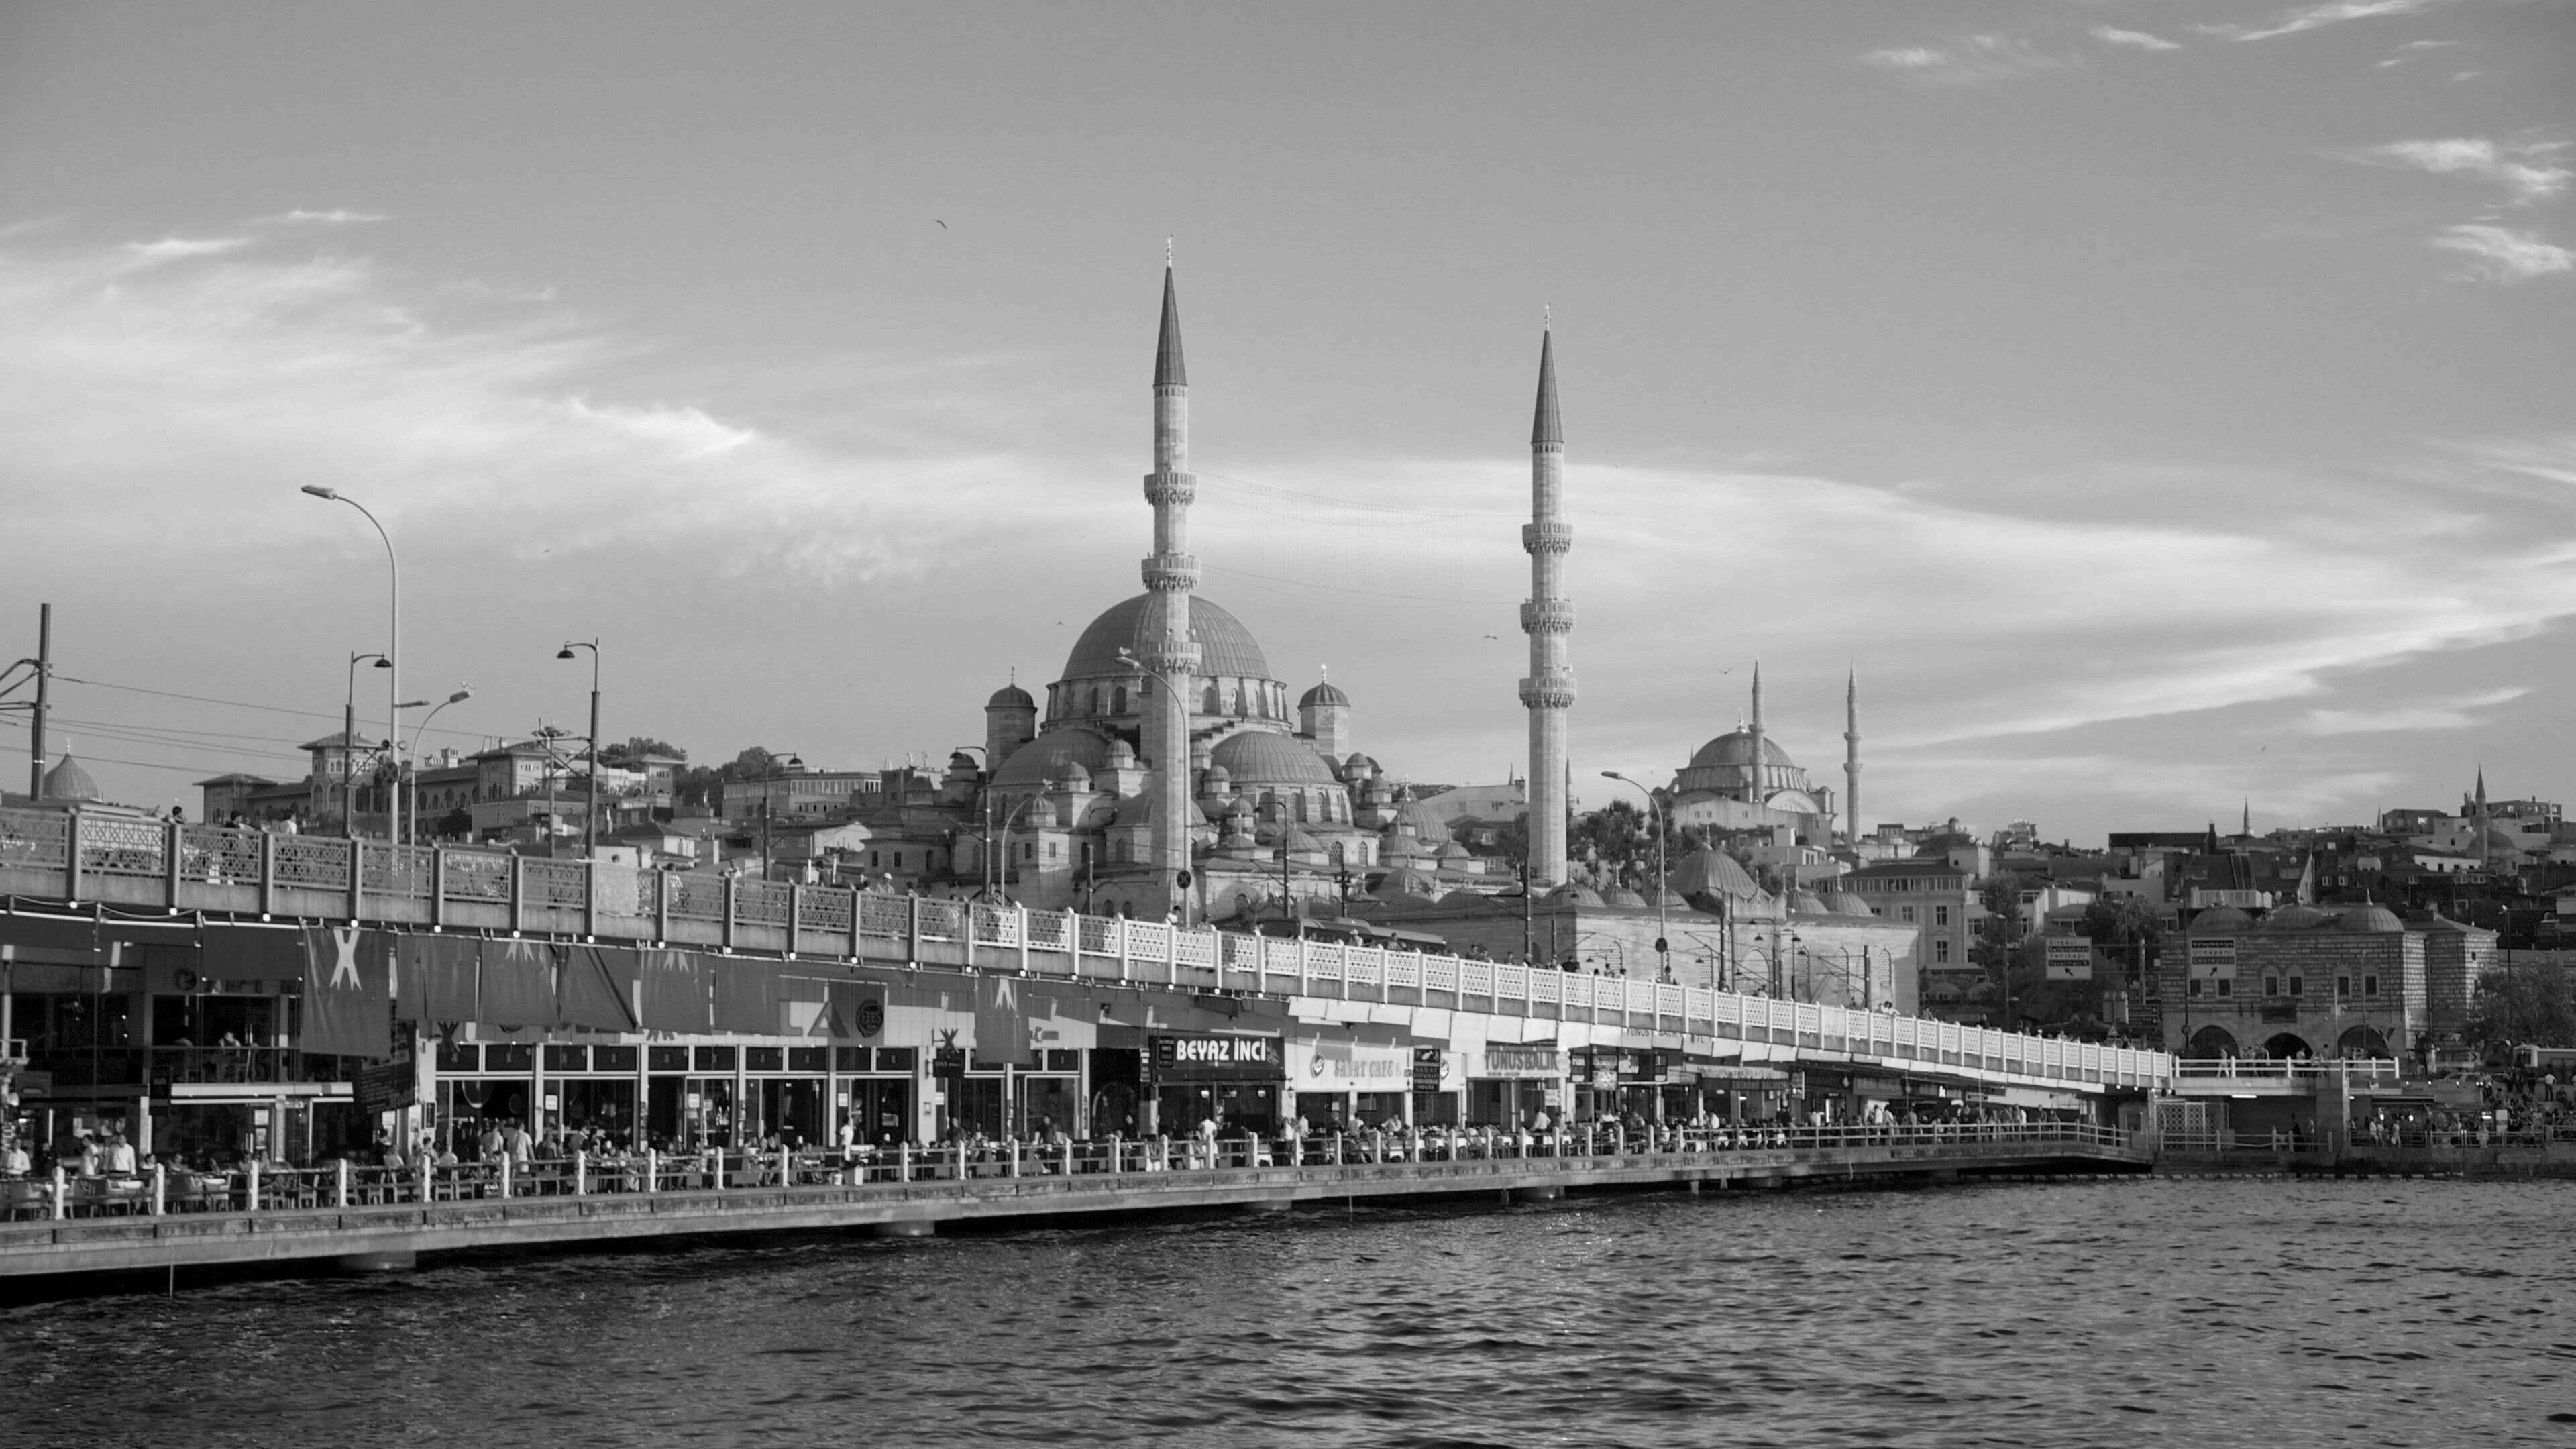

In [ ]:
from IPython.display import Image, display

print("--- Orijinal Resim ---")
display(Image('image2.2.jpg'))

print("--- Quantize Sonrası Resim ---")
display(Image('quantized_6bit.jpg'))